# Student Exam Performance Data Visualizer
**GetIntern.in | Week 3 Milestone Project | Visual Outlier Detection & Correlation Heatmaps**

This notebook uses **Pandas, Matplotlib and Seaborn** to detect outliers, explore score distributions, and find which factors correlate most strongly with exam performance.

**Objectives**
1. Outlier identification with boxplots
2. Distribution and categorical breakdowns
3. Correlation heatmap synthesis

## Setup
### Step 1: Import libraries
Pandas and NumPy handle the data, and Matplotlib and Seaborn draw the charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

### Step 2: Load the dataset
Load `StudentPerformanceFactors.csv`: 6,607 students and 20 columns, including study hours, attendance and exam score.

In [4]:
df = pd.read_csv("StudentPerformanceFactors.csv")
raw_shape = df.shape
print("Shape:", raw_shape)
df.head()

Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


### Step 3: Inspect the data
Standardize column names to lowercase, then check missing values, duplicates and summary statistics. There are no duplicates, and 235 values are missing in `teacher_quality` (78), `parental_education_level` (90) and `distance_from_home` (67).

In [5]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())
print(df.isnull().sum()[lambda s: s > 0])
print("Duplicates:", df.duplicated().sum())
df.describe().T

['hours_studied', 'attendance', 'parental_involvement', 'access_to_resources', 'extracurricular_activities', 'sleep_hours', 'previous_scores', 'motivation_level', 'internet_access', 'tutoring_sessions', 'family_income', 'teacher_quality', 'school_type', 'peer_influence', 'physical_activity', 'learning_disabilities', 'parental_education_level', 'distance_from_home', 'gender', 'exam_score']
teacher_quality             78
parental_education_level    90
distance_from_home          67
dtype: int64
Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
hours_studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
sleep_hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
previous_scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
tutoring_sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
physical_activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
exam_score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


### Step 4: Basic cleaning
Remove duplicates, strip whitespace, fill missing categorical values with the **mode** and any missing numeric values with the **median**. After this step there are 0 null values.

In [6]:
df = df.drop_duplicates()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].fillna(df[col].mode()[0])      # categorical -> mode

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())        # numeric -> median

print("Nulls left:", df.isnull().sum().sum(), "| Shape:", df.shape)

Nulls left: 0 | Shape: (6607, 20)


## Objective 1: Outlier Identification with Boxplots
### Step 5: Boxplots before capping
`seaborn.boxplot()` shows the spread of `exam_score`, `previous_scores` and `attendance`, plus `hours_studied` on its own scale. Points beyond the whiskers are outliers.

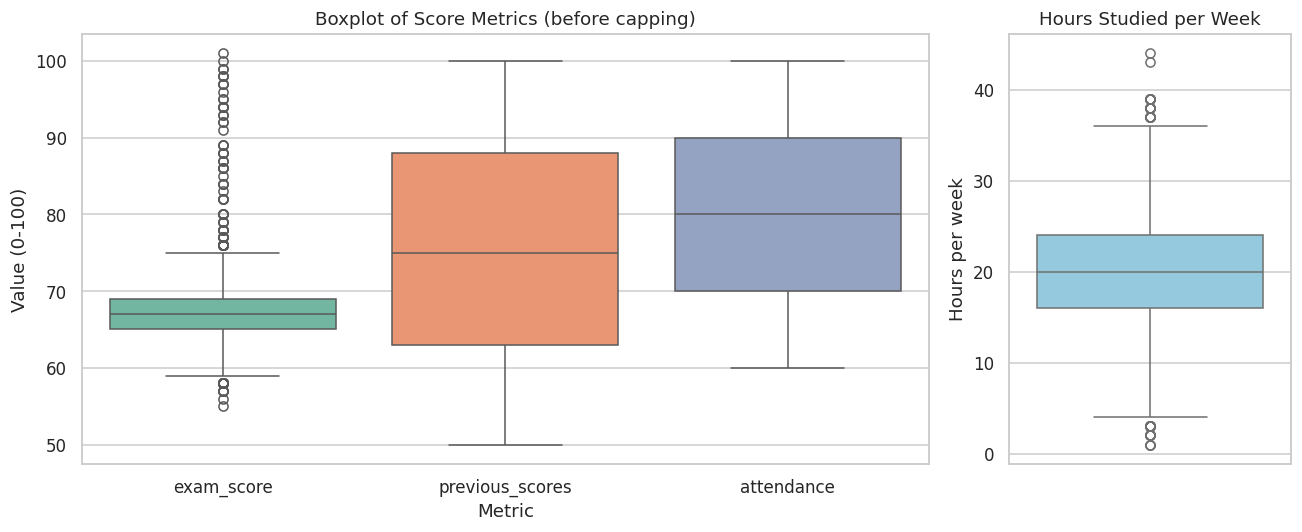

In [7]:
score_cols = ["exam_score", "previous_scores", "attendance"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(data=df[score_cols], ax=axes[0], palette="Set2")
axes[0].set_title("Boxplot of Score Metrics (before capping)")
axes[0].set_xlabel("Metric")
axes[0].set_ylabel("Value (0-100)")

sns.boxplot(y=df["hours_studied"], ax=axes[1], color="skyblue")
axes[1].set_title("Hours Studied per Week")
axes[1].set_ylabel("Hours per week")

plt.tight_layout()
plt.savefig("boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 6: IQR outlier bounds
Outliers are values below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**. `exam_score` has 104 outliers (bounds 59 to 75) and `hours_studied` has 43 (bounds 4 to 36). `previous_scores` and `attendance` have none.

In [8]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["exam_score", "previous_scores", "attendance", "hours_studied"]:
    low, high = iqr_bounds(df[col])
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append({"column": col, "lower_bound": round(low, 2), "upper_bound": round(high, 2),
                 "outliers": n_out, "min": df[col].min(), "max": df[col].max()})

outlier_table = pd.DataFrame(rows)
outlier_table

,column,lower_bound,upper_bound,outliers,min,max
0,exam_score,59.0,75.0,104,55,101
1,previous_scores,25.5,125.5,0,50,100
2,attendance,40.0,120.0,0,60,100
3,hours_studied,4.0,36.0,43,1,44


### Step 7: Inspect the outlier rows
Look at actual rows with extreme exam scores. One student scored 100 and another 89, while most scores sit between 65 and 69.

In [9]:
low, high = iqr_bounds(df["exam_score"])
df[(df["exam_score"] < low) | (df["exam_score"] > high)][["hours_studied", "attendance", "previous_scores", "exam_score"]].head(10)

,hours_studied,attendance,previous_scores,exam_score
94,18,89,73,100
106,31,100,59,76
113,35,99,85,79
209,43,86,97,78
217,19,70,54,89
404,17,77,53,86
529,15,83,97,97
558,22,70,53,83
560,22,71,56,84
637,20,65,62,80


### Step 8: Cap extreme values
Values outside the IQR bounds are capped with `.clip()` instead of dropped, so no students are lost. The maximum exam score, which was 101 and impossible on a 100-point scale, becomes 75.

In [10]:
df_clean = df.copy()
for col in ["exam_score", "previous_scores", "attendance", "hours_studied"]:
    low, high = iqr_bounds(df[col])
    df_clean[col] = df[col].clip(lower=low, upper=high)

print("Max exam score before:", df["exam_score"].max(), "| after:", df_clean["exam_score"].max())

Max exam score before: 101 | after: 75


### Step 9: Boxplot after capping
The same boxplot after capping. The exam score outliers are gone, and the distribution is tighter.

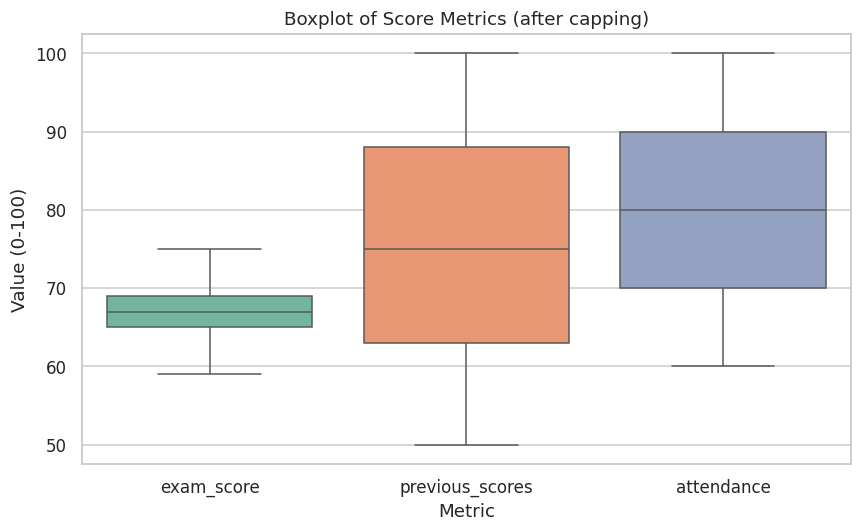

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean[["exam_score", "previous_scores", "attendance"]], palette="Set2")
plt.title("Boxplot of Score Metrics (after capping)")
plt.xlabel("Metric")
plt.ylabel("Value (0-100)")
plt.tight_layout()
plt.savefig("boxplot_after_capping.png", dpi=150, bbox_inches="tight")
plt.show()

## Objective 2: Distribution & Categorical Breakdowns
### Step 10: Score and study-hour distributions
`seaborn.histplot()` with a KDE curve shows how exam scores (mean about 67.1) and weekly study hours (mean about 20) are distributed. Both are roughly bell-shaped.

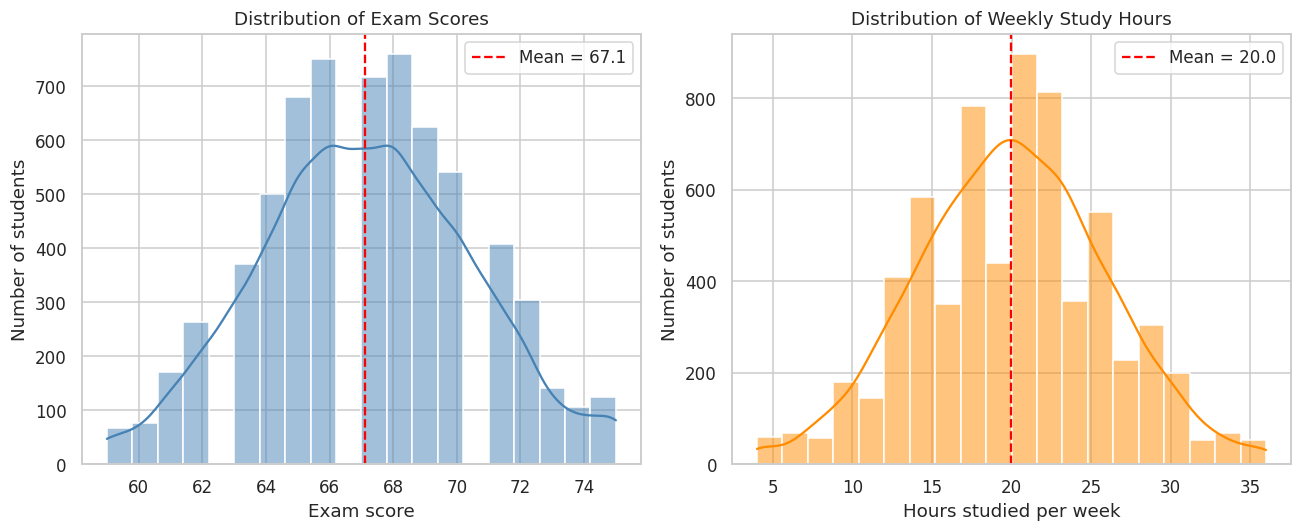

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_clean["exam_score"], bins=20, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df_clean["exam_score"].mean(), color="red", linestyle="--",
                label=f"Mean = {df_clean['exam_score'].mean():.1f}")
axes[0].set_title("Distribution of Exam Scores")
axes[0].set_xlabel("Exam score")
axes[0].set_ylabel("Number of students")
axes[0].legend()

sns.histplot(df_clean["hours_studied"], bins=20, kde=True, color="darkorange", ax=axes[1])
axes[1].axvline(df_clean["hours_studied"].mean(), color="red", linestyle="--",
                label=f"Mean = {df_clean['hours_studied'].mean():.1f}")
axes[1].set_title("Distribution of Weekly Study Hours")
axes[1].set_xlabel("Hours studied per week")
axes[1].set_ylabel("Number of students")
axes[1].legend()

plt.tight_layout()
plt.savefig("distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 11: Breakdowns by study hours and demographics
Compare performance across groups:
- **Study-hour bands:** average score rises steadily with more study time.
- **Gender:** distributions almost overlap, so there is little difference.
- **Parental involvement:** median score rises slightly from Low to High.

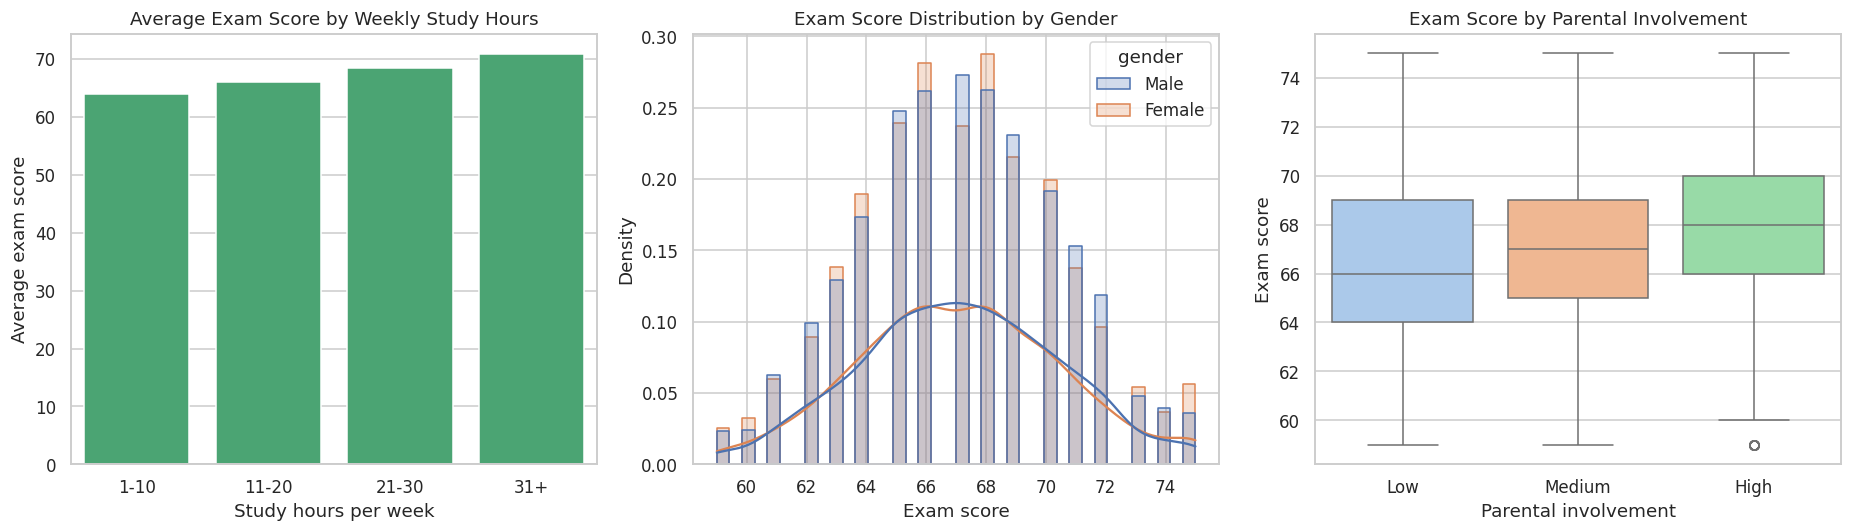

In [13]:
df_clean["study_band"] = pd.cut(df_clean["hours_studied"], bins=[0, 10, 20, 30, 50],
                                labels=["1-10", "11-20", "21-30", "31+"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=df_clean, x="study_band", y="exam_score", errorbar=None, color="mediumseagreen", ax=axes[0])
axes[0].set_title("Average Exam Score by Weekly Study Hours")
axes[0].set_xlabel("Study hours per week")
axes[0].set_ylabel("Average exam score")

sns.histplot(data=df_clean, x="exam_score", hue="gender", kde=True, element="step",
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Exam Score Distribution by Gender")
axes[1].set_xlabel("Exam score")
axes[1].set_ylabel("Density")

sns.boxplot(data=df_clean, x="parental_involvement", y="exam_score", order=["Low", "Medium", "High"], hue="parental_involvement", palette="pastel", legend=False, ax=axes[2])
axes[2].set_title("Exam Score by Parental Involvement")
axes[2].set_xlabel("Parental involvement")
axes[2].set_ylabel("Exam score")

plt.tight_layout()
plt.savefig("distribution_breakdowns.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 12: Score distribution for each study-hours group
Histogram curves for each study-hours band. As study time increases, the score curve shifts to the right.

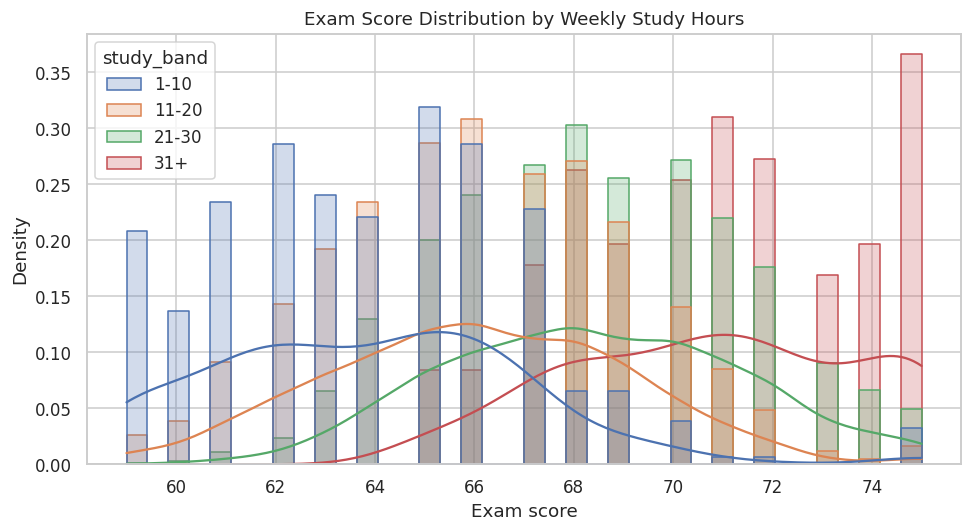

In [14]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="exam_score", hue="study_band", kde=True,
             element="step", stat="density", common_norm=False)
plt.title("Exam Score Distribution by Weekly Study Hours")
plt.xlabel("Exam score")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig("distribution_by_study_hours.png", dpi=150, bbox_inches="tight")
plt.show()

## Objective 3: Correlation Heatmap Synthesis
### Step 13: Correlation matrix
`df.corr()` calculates the correlation between every pair of numeric variables.

In [15]:
corr = df_clean.corr(numeric_only=True)
corr.round(2)

,hours_studied,attendance,sleep_hours,previous_scores,tutoring_sessions,physical_activity,exam_score
hours_studied,1.00,-0.01,0.01,0.02,-0.01,0.00,0.50
attendance,-0.01,1.00,-0.02,-0.02,0.01,-0.02,0.66
sleep_hours,0.01,-0.02,1.00,-0.02,-0.01,-0.00,-0.01
previous_scores,0.02,-0.02,-0.02,1.00,-0.01,-0.01,0.20
tutoring_sessions,-0.01,0.01,-0.01,-0.01,1.00,0.02,0.18
physical_activity,0.00,-0.02,-0.00,-0.01,0.02,1.00,0.04
exam_score,0.50,0.66,-0.01,0.20,0.18,0.04,1.00


### Step 14: Annotated heatmap
`seaborn.heatmap()` shows the matrix with the coefficients written in each cell. Red is positive and blue is negative.

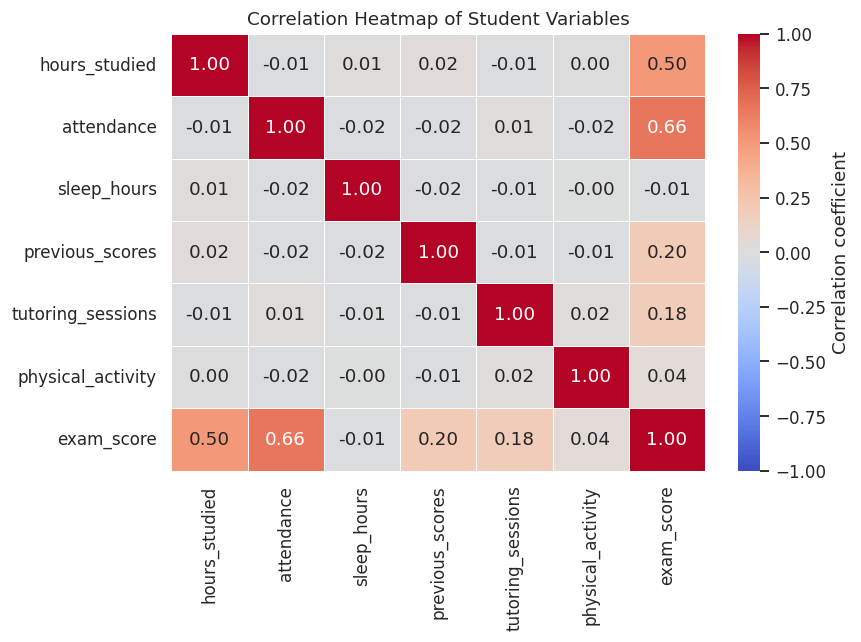

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation coefficient"})
plt.title("Correlation Heatmap of Student Variables")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 15: Variables most related to exam score
Ranking the correlations with `exam_score`: **attendance (0.66)** is strongest, followed by **hours studied (0.51)**. Previous scores and tutoring sessions are weak (about 0.2), and sleep and physical activity are close to zero.

In [17]:
exam_corr = corr["exam_score"].drop("exam_score").sort_values(ascending=False)
print(exam_corr.round(3))
print("\nStrongest positive:", exam_corr.index[0], "=", round(exam_corr.iloc[0], 3))

attendance           0.661
hours_studied        0.505
previous_scores      0.196
tutoring_sessions    0.175
physical_activity    0.037
sleep_hours         -0.014
Name: exam_score, dtype: float64

Strongest positive: attendance = 0.661


### Step 16: Save the cleaned dataset
Export the cleaned and capped dataset as `cleaned_student_performance.csv`.

In [18]:
df_clean.drop(columns="study_band").to_csv("cleaned_student_performance.csv", index=False)
print("Saved")

Saved


## Conclusion
- Found and capped **104 exam score outliers** and **43 study-hour outliers** using the IQR rule.
- Exam scores and study hours are roughly bell-shaped, and scores rise with study time.
- **Attendance (r = 0.66)** and **hours studied (r = 0.51)** correlate most strongly with high grades.
- Gender shows almost no difference, and parental involvement shows a small positive trend.